[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/eliem08/ai-agents-healthcare-labs/blob/main/notebooks/Lab02_QC_Agent.ipynb)

# Lab 2 — A QC agent for LC-MS/MS batches
**AI Agents for Healthcare and Diagnostics** · Module 2 · about 50 minutes

**The situation.** Every morning someone at Northbridge reviews last night's 25-OH vitamin D batches:
calibration, internal standard, ion ratios, Westgard rules on three QC levels. It is careful, repetitive work.
Can an agent do the review — and what must it **never** do on its own?

**At the end of this lab you will be able to:**
- give an agent several tools and **status rules**, and have it propose PASS, HOLD or ESCALATE;
- make sure every flag comes from a **tool**, never from the model's own arithmetic;
- rebuild a decision from an **audit log** written automatically by code;
- measure the agent against an answer key, and explain why a human keeps the final decision.

| Word | Meaning here |
|---|---|
| **Tool** | a Python function the agent can call; here it does all the QC arithmetic |
| **Status rules** | your laboratory's decision rules, written into the agent's instruction |
| **Callback** | code that runs automatically after every tool call — here it writes the audit log |

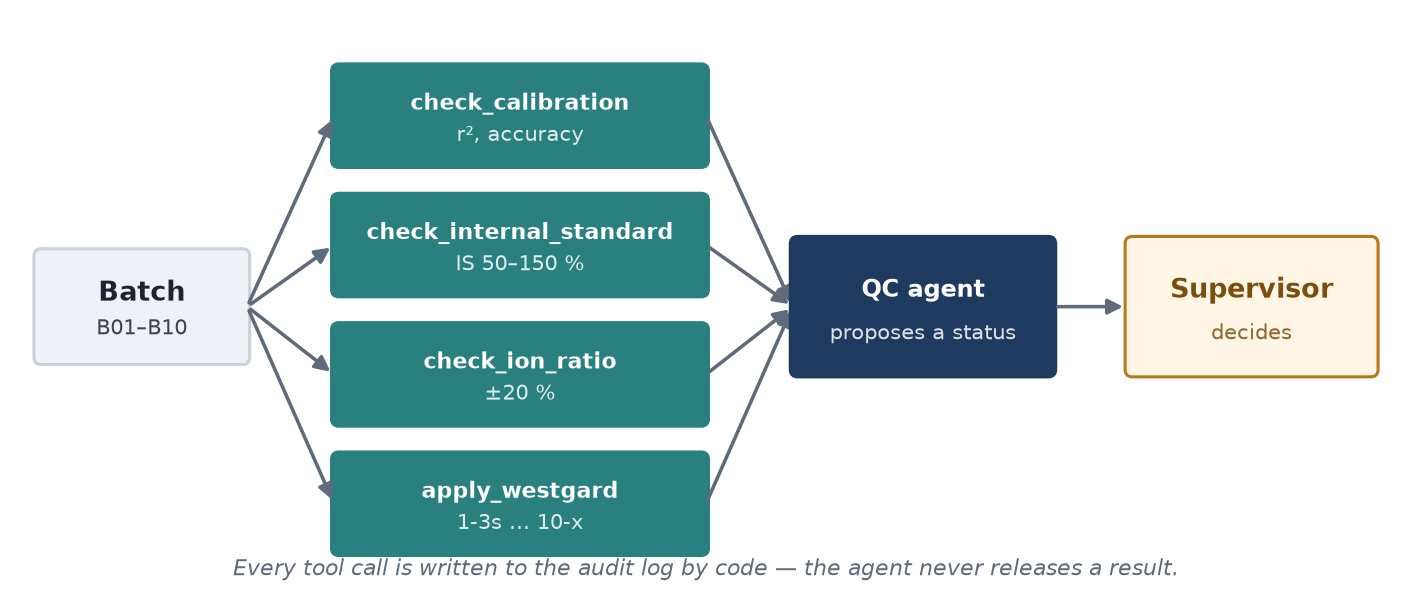

*The tools check; the agent proposes; the supervisor decides. The audit log records every step.*

### Setup — run this cell (about 1 minute)
Same as in Lab 0: it installs the course tools, downloads the course files and checks your key. The code is folded: just run it.

In [ ]:
# @title Setup — click run and wait about 1 minute
import os, subprocess, sys
REPO = "https://github.com/eliem08/ai-agents-healthcare-labs"
MODEL = "gemini-3.5-flash-lite"  # @param {type:"string"}
___ = "___"  # the blank you will replace in YOUR CELL

def _step(what, cmd):
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(f"FAILED: {what}. Run this cell again; if it fails twice, send the text below to the trainer:")
        print((r.stderr or r.stdout)[-800:])
        return False
    print(f"done: {what}")
    return True

try:
    import google.colab  # noqa: F401  — present only inside Colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

_ready = True
if IN_COLAB:
    if not os.path.exists("/content/course"):
        _ready = _step("download course files", ["git", "clone", "-q", "--depth", "1", REPO, "/content/course"])
    if _ready:
        _ready = _step("install Google ADK", [sys.executable, "-m", "pip", "install", "-q", "google-adk==2.15.0"])
    sys.path.insert(0, "/content/course")

SETUP_OK, SETUP_RESULTS = False, []
if _ready:
    from google.adk.agents import Agent
    from labkit.setup import check_environment, show_checks
    from labkit.agents import make_model, run, DETERMINISTIC
    from labkit.ui import check, has_blank, ready, copy_box, done_card
    import json
    import pandas as pd
    import matplotlib.pyplot as plt
    from IPython.display import HTML, display
    from labkit import DATA_DIR, REPO_URL
    from labkit import qc
    from labkit.audit import AuditLog
    from labkit.ui import error_line
    LAB = DATA_DIR / "lab02"
    DATA = qc.load(LAB)
    KEY = json.loads((LAB / "answer_key.json").read_text(encoding="utf-8"))
    QC_TOOLS = qc.make_qc_tools(DATA)
    check_calibration, check_internal_standard = QC_TOOLS["check_calibration"], QC_TOOLS["check_internal_standard"]
    check_ion_ratio, apply_westgard = QC_TOOLS["check_ion_ratio"], QC_TOOLS["apply_westgard"]
    draft_deviation = QC_TOOLS["draft_deviation"]
    LOG = AuditLog()
    SETUP_RESULTS = check_environment(MODEL, ping_pubmed=False)
    SETUP_OK = show_checks(SETUP_RESULTS)

**What you should see:** every line marked **OK**, then *"Everything is ready"*. Same Setup as Lab 0.

**If it does not work**

| You see | Do this |
|---|---|
| FIX — API key found | Open Secrets (key icon, left sidebar): `GOOGLE_API_KEY`, *Notebook access* on; run Setup again |
| FIX — API key works, "busy" or "quota" | Wait 30–60 seconds, run Setup again |
| FAILED: download / install | Run Setup again; if it fails twice, send the text to the trainer |
| `NameError: ... is not defined` in later cells | Session restarted: click the cell, then **Runtime → Run before** |

## Part 1 — The data (about 12 minutes)
Ten batches, B01 to B10, run on consecutive days. Each batch: 6 calibrators (5–150 ng/mL), three QC levels
(15, 50, 120 ng/mL) in duplicate, and 40 patient samples. The rules are those of SOP-01 (Lab 1).
Run the cell to see the first rows of batch B01.

In [ ]:
# @title Look at batch B01 — run this cell
_b = DATA.batch("B01")
print(_b.sample_type.value_counts().to_string(), "\n")
display(_b.head(12))

### Levey-Jennings chart
Choose a QC level and the last batch to show, then run the cell. Each dot is one QC result in SD units from
its target; the line is the run mean. Look at **QC-H up to B03**: no single result is alarming — but what
does the pattern tell you?

In [ ]:
# @title Levey-Jennings chart — choose, then run
level = "QC-H"  # @param ["QC-L", "QC-M", "QC-H"]
up_to_batch = "B03"  # @param ["B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08", "B09", "B10"]
qc.levey_jennings(DATA, level, upto=up_to_batch)
plt.show()

In [ ]:
# @title Download batch B04 as a CSV (for Task 1) — run this cell
_p = "/tmp/batch_B04.csv" if IN_COLAB else str(LAB / "batch_B04.csv")
DATA.batch("B04").to_csv(_p, index=False)
if IN_COLAB:
    from google.colab import files
    files.download(_p)
print("Saved:", _p)

### Task 1 — Ask Gemini to review a batch file
<sub>IN THE GEMINI APP · ABOUT 7 MIN</sub>

**Your task.** Give the raw batch to the Gemini app and see what a language model does with numbers — before giving it tools.

**Steps**

1. Open [gemini.google.com](https://gemini.google.com), attach `batch_B04.csv` and ask: *Review this LC-MS/MS batch. Which samples have an internal standard area below 50 % or above 150 % of the mean IS area of the calibrators and QCs? List the sample ids and the percentages.*
2. Compare its list with the truth printed by the CHECK below (computed by the tool).
3. Choose what Gemini did in the form, then run the cell and the CHECK. (Optional: ask Gemini's **Canvas** to draw a Levey-Jennings chart of the QC-H results.)

In [ ]:
# @title What did Gemini do?
# YOUR CELL — tick the boxes in the form, then run this cell
gemini_result = "choose…"  # @param ["choose…", "Exactly the right 5 samples, right percentages", "Right samples, wrong or missing percentages", "Missed samples or listed extra ones", "It wrote code to compute it (and showed the result)", "Gemini app not available to me"]

In [ ]:
# @title CHECK — run this cell: it tells you what is right and what to fix
_truth = check_internal_standard("B04")
print("Truth (tool):", ", ".join(f"{f['sample_id']} {f['is_area_pct']} %" for f in _truth["flagged_samples"]))
_ok = check([(gemini_result != "choose…", "Gemini's result recorded", "Choose an option in the form.")])
if _ok:
    GEMINI_RESULT = gemini_result

<details><summary><b>Hint</b> — open only if you are stuck</summary>

Language models read numbers as text: means and percentages over 52 rows are easy to get slightly wrong, and the answer sounds equally confident either way. If Gemini wrote and ran code, that is the right instinct — it is exactly what the agent's tools do.

</details>

## Part 2 — Build and test the QC agent (about 30 minutes)
The four check tools are ready (they apply SOP-01 exactly). Try one by hand: what does it return for B02?

In [ ]:
check_calibration("B02")   # try check_internal_standard("B04"), apply_westgard("B06")…

### Task 2 — Write the QC agent's instruction and choose its tools
<sub>IN THE NOTEBOOK · ABOUT 8 MIN</sub>

**Your task.** Turn your laboratory's review procedure into rules an agent must follow.

**Steps**

1. **Use all checks:** call check_calibration, check_internal_standard, check_ion_ratio and apply_westgard.
2. **No arithmetic:** never compute or estimate a value itself — only use the tools' numbers.
3. **Traceability:** report every flag with the name of the tool that found it.
4. **Status rules:** Westgard violation or failed calibration = ESCALATE; IS or ion-ratio flags on patient samples = HOLD those samples; nothing found = PASS.
5. **Human decides:** if HOLD or ESCALATE, call draft_deviation for the supervisor; never release results.
6. **Fixed ending:** finish with `STATUS: …` and `SAMPLES ON HOLD: …` (the scoreboard reads these two lines).
7. Set `TOOLS` to the five tools (no quotes), then run your cell and the CHECK.

In [ ]:
# YOUR CELL — replace every ___ , then run this cell
QC_INSTRUCTION = """___"""
TOOLS = [___]

In [ ]:
# @title CHECK — run this cell: it tells you what is right and what to fix
_i = QC_INSTRUCTION.lower()
_blank = has_blank(QC_INSTRUCTION)
_names = {getattr(t, "__name__", "") for t in TOOLS} if isinstance(TOOLS, list) else set()
if _blank:
    _ok = check([(False, "Instruction written", _blank)])
else:
    _ok = check([
        (all(n in _i for n in ("check_calibration", "check_internal_standard", "check_ion_ratio", "apply_westgard"))
         or "all" in _i, "Uses all four checks", "Name the four check tools, or say it must call ALL of them."),
        (any(w in _i for w in ("never compute", "do not compute", "don't compute", "not calculate", "never calculate")),
         "No arithmetic by the model", "Write: never compute or estimate any value yourself."),
        (all(s in _i for s in ("pass", "hold", "escalate")), "Status rules: PASS / HOLD / ESCALATE",
         "Write the three status rules."),
        ("status:" in _i and "samples on hold" in _i, "Fixed ending (STATUS / SAMPLES ON HOLD)",
         "End the instruction with: STATUS: … and SAMPLES ON HOLD: …"),
        ({"check_calibration", "check_internal_standard", "check_ion_ratio", "apply_westgard",
          "draft_deviation"} <= _names, "TOOLS contains the five tools",
         "TOOLS = [check_calibration, check_internal_standard, check_ion_ratio, apply_westgard, draft_deviation]"),
    ])

<details><summary><b>Hint</b> — open only if you are stuck</summary>

Write it as a short procedure, one rule per line. The two fixed last lines matter: code reads them to score the agent — a format contract between the model and your software.

</details>

<details><summary><b>Solution</b> — open only after trying</summary>

```python
QC_INSTRUCTION = """You are the QC reviewer for the Northbridge 25-OH vitamin D LC-MS/MS method.
To review a batch, call ALL four checks: check_calibration, check_internal_standard, check_ion_ratio and apply_westgard.
Never compute or estimate any value yourself: use only the numbers returned by the tools.
Report every flag with the name of the tool that found it.
Status rules: any Westgard violation or a failed calibration = ESCALATE. Otherwise, internal standard or ion ratio flags on patient samples = HOLD those samples. Nothing found = PASS.
If the status is HOLD or ESCALATE, call draft_deviation for the supervisor. You never release or reject results yourself: a human decides.
End your report with exactly two lines:
STATUS: <PASS, HOLD or ESCALATE>
SAMPLES ON HOLD: <comma-separated sample ids, or none>"""
TOOLS = [check_calibration, check_internal_standard, check_ion_ratio, apply_westgard, draft_deviation]
```

</details>

### Build the agent and review the clean batch B01

In [ ]:
if ready("qc_reviewer", QC_INSTRUCTION, TOOLS, example="check_calibration"):
    qc_agent = Agent(name="qc_reviewer", model=make_model(MODEL), instruction=QC_INSTRUCTION, tools=TOOLS,
                     generate_content_config=DETERMINISTIC,
                     after_tool_callback=LOG.callback)   # the audit log is written by code, after every tool call
    _r = run(qc_agent, "Review batch B01.")
    print("Parsed:", qc.parse_status(_r.text))
else:
    qc_agent = None

### Review batches B02–B06 and compare with the answer key
The next cell asks the agent to review five batches (two at a time, about 1–2 minutes), then shows its
proposals next to the answer key. Each batch has one planted problem.

In [ ]:
# @title Review B02–B06 and score against the answer key — run this cell
if qc_agent is None:
    display(error_line("Build the agent first (Task 2 and the cell after it)."))
else:
    CORE_RESULTS = qc.run_batches(qc_agent, ['B02', 'B03', 'B04', 'B05', 'B06'], LOG)
    _html, CORE_SCORE = qc.scoreboard_html(CORE_RESULTS, KEY)
    display(HTML(_html))
    print(f"Post in the course chat → QC agent: {CORE_SCORE}/5 batches right")

### Task 3 — Rebuild a decision from the audit log
<sub>IN THE NOTEBOOK · ABOUT 6 MIN</sub>

**Your task.** An auditor asks: why were samples of batch B04 held? Answer from the audit log only — the record written by code, not the agent's own report.

**Steps**

1. Run the first cell below: it shows the audit log for B04.
2. Find which tool found the problem, which samples, and what the agent proposed.
3. Fill the form as the supervisor, then run it and the CHECK.

In [ ]:
# @title Audit log for batch B04 — run this cell
if LOG.for_batch("B04"):
    display(HTML(LOG.html("B04")))
else:
    display(error_line("No entry for B04 yet: run the B02–B06 review first."))

In [ ]:
# @title Your reading of the B04 audit log
# YOUR CELL — tick the boxes in the form, then run this cell
tool_that_found_it = "choose…"  # @param ["choose…", "check_calibration", "check_internal_standard", "check_ion_ratio", "apply_westgard"]
samples_held = ""  # @param {type:"string"}
supervisor_action = "choose…"  # @param ["choose…", "Approve the hold and ask for re-injection of these samples", "Release all results", "Reject the whole batch"]

In [ ]:
# @title CHECK — run this cell: it tells you what is right and what to fix
import re as _re
_held = sorted(set(_re.findall(r"B04-S\d{2}", samples_held.upper())))
_ok = check([
    (tool_that_found_it == "check_internal_standard", "Tool identified",
     "Look at the 'Result recorded' column: which check reported flagged samples?"),
    (_held == KEY["B04"]["samples_on_hold"], "Samples identified (5, consecutive)",
     "Copy the five sample ids from the audit log, e.g. B04-S11, B04-S12, …"),
    (supervisor_action.startswith("Approve the hold"), "Supervisor action",
     "An IS drop on consecutive samples suggests an injection problem: hold and re-inject those samples."),
])
if _ok:
    AUDIT_DONE = True

<details><summary><b>Hint</b> — open only if you are stuck</summary>

The log has one row per tool call, recorded automatically after the call, plus the agent's proposal. Five consecutive samples with the IS at about 40 % point to an injection problem, not to the patients.

</details>

### The exam batches B07–B10
Four new batches. Run the cell (about 1 minute) and compare with the answer key.

In [ ]:
# @title Review the exam batches B07–B10 — run this cell
if qc_agent is None:
    display(error_line("Build the agent first (Task 2 and the cell after it)."))
else:
    EXAM_RESULTS = qc.run_batches(qc_agent, ['B07', 'B08', 'B09', 'B10'], LOG)
    _html, EXAM_SCORE = qc.scoreboard_html(EXAM_RESULTS, KEY)
    display(HTML(_html))

### Task 4 — What can your agent not see?
<sub>IN THE NOTEBOOK · ABOUT 5 MIN</sub>

**Your task.** One exam batch passes all four checks although something is wrong with it. Find the missing check.

**Steps**

1. In the exam table, find the batch whose answer key mentions a problem the agent did not report.
2. Run the first lines of the CHECK once with the blank form: it prints that batch's retention times.
3. Choose the missing check in the form, then run your cell and the CHECK.

In [ ]:
# @title Which check is missing?
# YOUR CELL — tick the boxes in the form, then run this cell
missing_check = "choose…"  # @param ["choose…", "Retention time", "Calibration", "Internal standard", "Westgard"]

In [ ]:
# @title CHECK — run this cell: it tells you what is right and what to fix
print(DATA.batch("B10").query("sample_type == 'patient'")[["sample_id", "retention_time"]].head(8).to_string(index=False))
_ok = check([(missing_check == "Retention time", "Missing check identified",
              "Look at the retention times printed above for B10: are some samples late?")])
if _ok:
    MISSING_CHECK = missing_check

<details><summary><b>Hint</b> — open only if you are stuck</summary>

B10 passes all four checks. Look at its retention times: S04–S06 elute about 0.2 min late. No tool looks at retention time — so the agent cannot see it. An agent is only as good as its tools.

</details>

## Discussion (7 minutes, with the group)
1. Why must the agent **never** release or reject results itself, even when it is right 5 times out of 5?
2. Why is "never compute a value yourself" in the instruction? What did Task 1 show?
3. The audit log is written by a **callback**, not by the agent. Why does that matter for an inspector?
4. Which checks do you run every day that this agent does not have? *(Keep your answer: it feeds the capstone.)*

### Task 5 — Write the missing tool: check_retention_time
<sub>OPTIONAL CHALLENGE · ABOUT 10 MIN</sub>

**Your task.** For fast finishers. Write a fifth tool, give it to a new agent, and re-review B10.

**Steps**

1. Complete the two blanks: the tolerance (0.10 minutes) and the comparison.
2. Run your cell, then the CHECK: it builds `qc_agent_rt` with your tool and reviews B10.

In [ ]:
# YOUR CELL — replace every ___ , then run this cell
def check_retention_time(batch_id: str) -> dict:
    """Flag samples whose retention time differs from the calibrator mean by more than 0.10 minutes.
    batch_id is like 'B01'."""
    b = DATA.batch(batch_id)
    ref = b[b.sample_type == "calibrator"].retention_time.mean()
    tolerance = ___
    flagged = [{"sample_id": s, "sample_type": t, "shift_min": round(rt - ref, 3)}
               for s, t, rt in zip(b.sample_id, b.sample_type, b.retention_time) if ___]
    return {"batch_id": batch_id, "calibrator_mean_rt_min": round(ref, 3), "flagged_samples": flagged}

In [ ]:
# @title CHECK — run this cell: it tells you what is right and what to fix
try:
    _rt = check_retention_time("B10")
    _ids = sorted(f["sample_id"] for f in _rt["flagged_samples"])
except Exception as _e:
    _ids = []
    display(error_line(f"Your tool raised an error: {_e}"))
_ok = check([(_ids == ["B10-S04", "B10-S05", "B10-S06"], "Tool flags B10-S04, S05, S06",
              "Use abs(rt - ref) > tolerance, with tolerance = 0.10.")])
if _ok and qc_agent is not None:
    qc_agent_rt = Agent(name="qc_reviewer", model=make_model(MODEL), tools=TOOLS + [check_retention_time],
                        instruction=QC_INSTRUCTION.replace("apply_westgard", "apply_westgard, check_retention_time")
                        + "\nRetention time flags on patient samples = HOLD those samples.",
                        generate_content_config=DETERMINISTIC, after_tool_callback=LOG.callback)
    _r = run(qc_agent_rt, "Review batch B10.")
    print("Parsed:", qc.parse_status(_r.text))

<details><summary><b>Hint</b> — open only if you are stuck</summary>

`abs(rt - ref) > tolerance` — the same pattern as the other checks. Note the instruction also needs a status rule for the new flag: a tool alone is not enough.

</details>

## What you learned
1. **Tools do the arithmetic, the agent decides what to call and how to report.** A language model reading
   numbers as text is not a QC calculator.
2. **Status rules + a fixed output format** turn a free-text answer into something software can check.
3. **The audit log is written by code** (a callback), so it records what really happened.
4. **An agent only sees what its tools see** (B10) — and a human keeps the release decision.

## Finish — your status card
Type your name, run the cell, post a screenshot in the course chat.

In [ ]:
# @title Status card — type your name, run, then screenshot the card
participant_name = ""  # @param {type:"string"}
import datetime
_g = globals()
_lines = [f"Participant: {participant_name.strip() or 'NAME MISSING — type it in the box'}",
          f"Date: {datetime.date.today().isoformat()} · model {_g.get('MODEL', '?')}",
          f"{'OK ' if 'GEMINI_RESULT' in _g else 'n/a'} — Gemini app batch review (Task 1, optional)",
          f"{'OK ' if 'CORE_SCORE' in _g else 'FIX'} — QC agent on B02–B06: {_g.get('CORE_SCORE', '?')}/5 batches right",
          f"{'OK ' if 'AUDIT_DONE' in _g else 'FIX'} — Decision rebuilt from the audit log (Task 3)",
          f"{'OK ' if 'MISSING_CHECK' in _g else 'FIX'} — Exam: missing check found (Task 4)",
          f"Audit log: {len(LOG.entries)} entries recorded automatically"]
done_card("Lab 2 — status", _lines, complete=bool(participant_name.strip()) and all(
    k in _g for k in ("CORE_SCORE", "AUDIT_DONE", "MISSING_CHECK")))

**Next: Lab 3 — Risk prediction agent.** A prediction model becomes a tool — and a guardrail in code stops the
agent from predicting on impossible inputs.

*Course material for training only. Northbridge Clinical & Research Laboratory and its data are fictional.*